In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sample_categorical(p, context=''):
    p = np.asarray(p, dtype=float)
    p = p / p.sum()
    return np.random.choice(len(p), p=p)

def awrs_a(p, cond, draw=sample_categorical):
    p_cond = p.copy()
    n, psi = 0, 0
    xc0 = None
    for i in range(2):
        while True:
            x = draw(p_cond / p_cond.sum(), context=('awrs', i, xc0))
            if cond(x):
                if i == 0:
                    xc0 = x
                break
            else:
                if i == 0:
                    psi += p_cond[x]
                p_cond[x] = 0
            n += 1
    return xc0, (1 - psi) / (n + 1)

def awrs_b(p, cond, draw=sample_categorical):
    p_cond = p.copy()
    n, psi = 0, 0
    xc0 = None
    for i in range(2):
        while True:
            x = draw(p_cond / p_cond.sum(), context=('awrs', i, xc0))
            if cond(x):
                if i == 0:
                    xc0 = x
                break
            else:
                if i == 0:
                    psi += p_cond[x]
                p_cond[x] = 0
            n += 1
    return xc0, (1 + psi) / (n + 1)

def awrs_c(p, cond, draw=sample_categorical):
    p_cond = p.copy()
    n, psi = 0, 0
    xc0 = None
    for i in range(2):
        while True:
            x = draw(p_cond / p_cond.sum(), context=('awrs', i, xc0))
            if cond(x):
                if i == 0:
                    xc0 = x
                break
            else:
                psi += p_cond[x]
                p_cond[x] = 0
            n += 1
    return xc0, (1 - psi) / (n + 1)

def awrs_d(p, cond, draw=sample_categorical):
    p_cond = p.copy()
    n, psi = 0, 0
    xc0 = None
    for i in range(2):
        while True:
            x = draw(p_cond / p_cond.sum(), context=('awrs', i, xc0))
            if cond(x):
                if i == 0:
                    xc0 = x
                break
            else:
                if i == 0:
                    psi += p_cond[x]
                p_cond[x] = 0
            n += 1
    return xc0, (1 - psi) / (n + 2)

variants = {'A': awrs_a, 'B': awrs_b, 'C': awrs_c, 'D': awrs_d}

np.random.seed(0)
N = 4
p = np.random.dirichlet(np.ones(N))
cond = np.random.uniform(0, 1, size=N) < 0.5
Z = p[cond].sum()
target = p * cond

In [2]:
np.random.seed(0)
reps = 1_000
for name, awrs in variants.items():
    have = np.zeros(N)
    for r in range(1, 1 + reps):
        (x, w) = awrs(p, lambda x: cond[x])
        have[x] += w
    err = abs(have / reps - target).sum()
    print(f'Variant {name}: error = {err:.6f}')

Variant A: error = 0.025367
Variant B: error = 0.163426
Variant C: error = 0.051898
Variant D: error = 0.173738


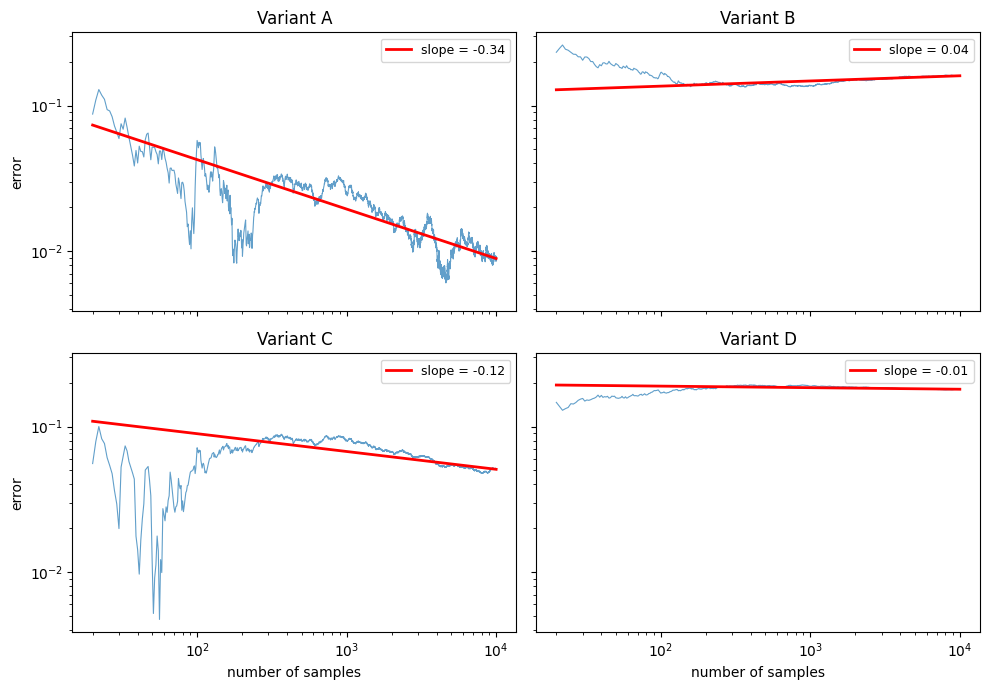

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

for ax, (name, awrs) in zip(axes.flat, variants.items()):
    np.random.seed(0)
    M = 10_000
    have = np.zeros(N)
    xs, ys = [], []
    for r in range(1, 1 + M):
        (item, w) = awrs(p, lambda x: cond[x])
        have[item] += w
        if r >= 20:
            xs.append(r)
            ys.append(abs(have / r - target).sum())
    slope, intercept = np.polyfit(np.log(xs), np.log(ys), deg=1)
    ax.plot(xs, ys, alpha=0.7, lw=0.8)
    ax.plot(xs, np.exp(np.log(xs) * slope + intercept), c='r', lw=2,
            label=f'slope = {slope:.2f}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(f'Variant {name}')
    ax.legend(fontsize=9)

axes[1,0].set_xlabel('number of samples')
axes[1,1].set_xlabel('number of samples')
axes[0,0].set_ylabel('error')
axes[1,0].set_ylabel('error')
fig.tight_layout()
plt.show()

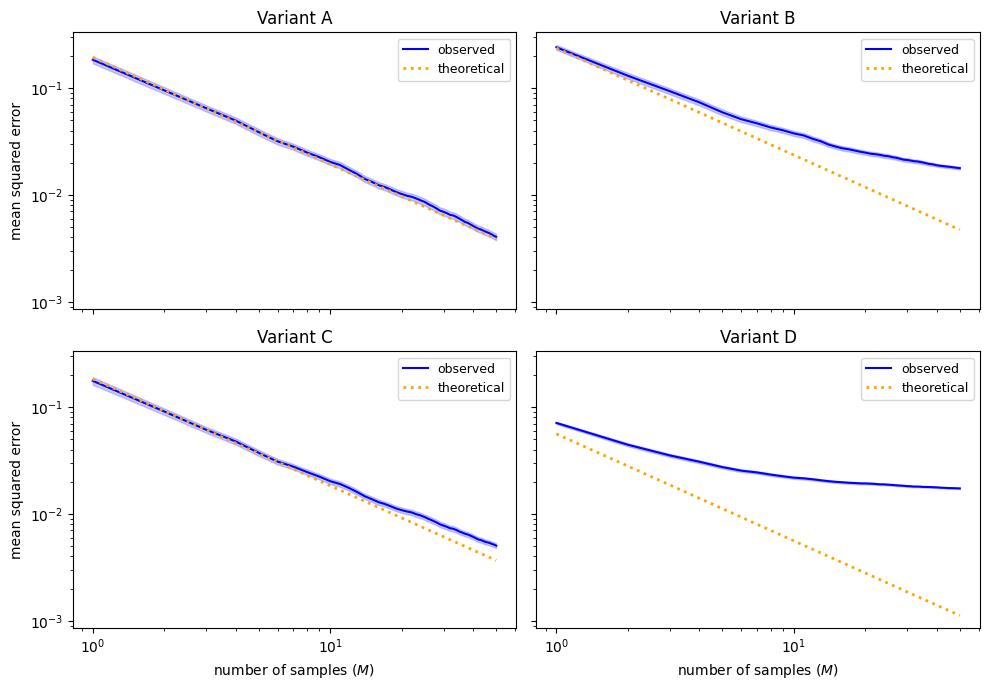

In [4]:
from scipy import stats

def mean_confidence_interval(data, confidence=0.95):
    n = len(data)
    m = np.mean(data)
    se = stats.sem(data)
    h = se * stats.t.ppf((1 + confidence) / 2, n - 1)
    return m, m - h, m + h

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

for ax, (name, awrs) in zip(axes.flat, variants.items()):
    np.random.seed(0)
    reps = 1000
    M = 50
    ms = list(range(1, 1 + M))
    runs_ys = []
    samples = []
    for r in range(1, 1 + reps):
        ys = []
        have = np.zeros(N)
        for m in ms:
            (item, w) = awrs(p, lambda x: cond[x])
            have[item] += w
            onehot = np.zeros(N)
            onehot[item] = w
            samples.append(onehot)
            ys.append(np.linalg.norm(have / m - target)**2)
        runs_ys.append(ys)
    runs_ys = np.array(runs_ys)
    C = np.cov(np.array(samples).T)
    V = np.trace(C)
    cis = [mean_confidence_interval(runs_ys[:, m]) for m in range(M)]
    means = [x[0] for x in cis]
    lowers = [x[1] for x in cis]
    uppers = [x[2] for x in cis]
    ax.plot(ms, means, c='b', label='observed')
    ax.fill_between(ms, lowers, uppers, alpha=0.2, color='b')
    ax.plot(ms, V / np.array(ms), label='theoretical',
            c='orange', zorder=10, lw=2, linestyle=':')
    ax.set_title(f'Variant {name}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.legend(fontsize=9)

axes[1,0].set_xlabel(r'number of samples ($M$)')
axes[1,1].set_xlabel(r'number of samples ($M$)')
axes[0,0].set_ylabel('mean squared error')
axes[1,0].set_ylabel('mean squared error')
fig.tight_layout()
plt.show()

In [5]:
import html as html_module
from graphviz import Digraph

class Node:
    def __init__(self, idx, mass, parent, token=None):
        self.idx = idx
        self.mass = mass
        self.parent = parent
        self.token = token
        self.child_masses = None
        self.active_children = {}
        self._mass = mass
        self.context = None

    def sample(self):
        cm = self.child_masses
        p = cm / cm.sum()
        return np.random.choice(len(p), p=p)

    def update(self):
        if self.parent is not None:
            self.parent.child_masses[self.idx] = self.mass
            self.parent.mass = np.sum(self.parent.child_masses)
            self.parent.update()

    def graphviz(self):
        g = Digraph(
            graph_attr=dict(rankdir='LR'),
            node_attr=dict(fontname='Monospace', fontsize='10',
                           height='.05', width='.05', margin='0.055,0.042'),
            edge_attr=dict(arrowsize='0.3', fontname='Monospace', fontsize='9'),
        )
        counter = [0]
        ids = {}
        def get_id(node):
            if id(node) not in ids:
                ids[id(node)] = str(counter[0])
                counter[0] += 1
            return ids[id(node)]
        q = [self]
        visited = set()
        while q:
            x = q.pop()
            if id(x) in visited: continue
            visited.add(id(x))
            label = ''
            if x.context:
                label += f'{x.context}\n'
            label += f'{x._mass:.2g}'
            g.node(get_id(x), label=label, shape='box')
            if x.child_masses is not None:
                for a, y in x.active_children.items():
                    tok = y.token if y.token is not None else a
                    edge_label = f'{html_module.escape(str(tok))}/{y._mass/x._mass:.2g}'
                    g.edge(get_id(x), get_id(y), label=edge_label)
                    q.append(y)
        return g

class Tracer:
    def __init__(self):
        self.root = Node(idx=-1, mass=1.0, parent=None)
        self.cur = None

    def __call__(self, p, context=None):
        if isinstance(p, dict):
            keys = list(p.keys())
            vals = np.array([p[k] for k in keys])
        else:
            p = np.asarray(p, dtype=float)
            keys = list(range(len(p)))
            vals = p
        vals = vals / vals.sum()
        cur = self.cur
        if cur.child_masses is None:
            cur.child_masses = cur.mass * vals
            cur.context = context
        a = cur.sample()
        if a not in cur.active_children:
            cur.active_children[a] = Node(
                idx=a, mass=cur.child_masses[a], parent=cur, token=keys[a])
        self.cur = cur.active_children[a]
        return keys[a]

class TraceSWOR(Tracer):
    def __enter__(self):
        self.cur = self.root
    def __exit__(self, *args):
        self.cur.mass = 0
        self.cur.update()

In [6]:
for name, awrs in variants.items():
    tracer = TraceSWOR()
    prob = np.zeros(N)
    while tracer.root.mass > 0:
        with tracer:
            (item, w) = awrs(p, lambda x: cond[x], draw=tracer)
            prob[item] += w * tracer.cur.mass
    err = abs(target - prob).sum()
    status = '\u2713' if np.allclose(target, prob) else '\u2717'
    print(f'Variant {name}: {status}  (error = {err:.2e})')

Variant A: ✓  (error = 5.55e-17)
Variant B: ✗  (error = 1.60e-01)
Variant C: ✗  (error = 4.99e-02)
Variant D: ✗  (error = 1.80e-01)


In [7]:
from collections import namedtuple

EOS = '<EOS>'

class SimpleLM:
    def __init__(self, sequences):
        self.sequences = sequences
    def p_next(self, prefix):
        dist = {}
        for seq, prob in self.sequences.items():
            if len(seq) < len(prefix): continue
            if seq[:len(prefix)] != prefix: continue
            if len(seq) == len(prefix):
                dist[EOS] = dist.get(EOS, 0) + prob
            else:
                token = seq[len(prefix)]
                dist[token] = dist.get(token, 0) + prob
        total = sum(dist.values())
        return {k: v / total for k, v in dist.items()}

Particle = namedtuple('Particle', 'weight, string')

def sample_dict(d, context=None):
    keys = list(d.keys())
    vals = np.array([d[k] for k in keys])
    vals = vals / vals.sum()
    idx = np.random.choice(len(keys), p=vals)
    return keys[idx]

def sequential_importance_sampling(p, q, M, draw=sample_dict):
    unfinished = [Particle(1, ()) for _ in range(M)]
    finished = []
    while unfinished:
        next_unfinished = []
        for particle in unfinished:
            P = p.p_next(particle.string)
            Q = q.p_next(particle.string)
            x = draw(Q)
            if x == EOS:
                finished.append(Particle(particle.weight * P[x] / Q[x], particle.string))
            else:
                next_unfinished.append(Particle(particle.weight * P[x] / Q[x], particle.string + (x,)))
        unfinished = next_unfinished
    return finished

p_lm = SimpleLM({('a', 'a'): 0.3, ('b', 'b', 'b'): 0.6, (): 0.1})
q_lm = SimpleLM({('a', 'a'): 0.2, ('b', 'b', 'b'): 0.7, (): 0.1})

Z estimate (exact via tracing): 1.000000
Z true:                         1.000000
✓ SIS is unbiased


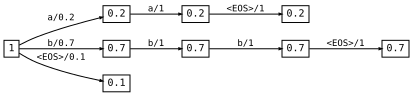

In [8]:
tracer = TraceSWOR()
have = 0
while tracer.root.mass > 0:
    with tracer:
        finished = sequential_importance_sampling(p_lm, q_lm, M=1, draw=tracer)
        Z_hat = sum(pt.weight for pt in finished)
        have += Z_hat * tracer.cur.mass

print(f'Z estimate (exact via tracing): {have:.6f}')
print(f'Z true:                         1.000000')
assert abs(have - 1.0) < 1e-10
print('\u2713 SIS is unbiased')
tracer.root.graphviz()

In [9]:
def sequential_importance_resampling(p, q, M, tau, draw=sample_dict):
    unfinished = [Particle(1, ()) for _ in range(M)]
    finished = []
    t = 0
    while True:
        t += 1
        next_unfinished = []
        for m, particle in enumerate(unfinished):
            P = p.p_next(particle.string)
            Q = q.p_next(particle.string)
            x = draw(Q, context=(t, m))
            if x == EOS:
                finished.append(Particle(particle.weight * P[x] / Q[x], particle.string))
            else:
                next_unfinished.append(Particle(particle.weight * P[x] / Q[x], particle.string + (x,)))
        unfinished = next_unfinished
        if not unfinished: break
        W = sum(pt.weight for pt in unfinished)
        W2 = sum(pt.weight**2 for pt in unfinished)
        M_eff = W**2 / W2
        if M_eff < tau * M:
            distr = {k: pt.weight / W for k, pt in enumerate(unfinished)}
            indices = [draw(distr, context=('resample', t, m)) for m in range(M)]
            avg_weight = W / M
            unfinished = [Particle(avg_weight, unfinished[k].string) for k in indices]
    return finished

Z estimate (exact via tracing): 1.000000
Z true:                         1.000000
✓ SIR is unbiased


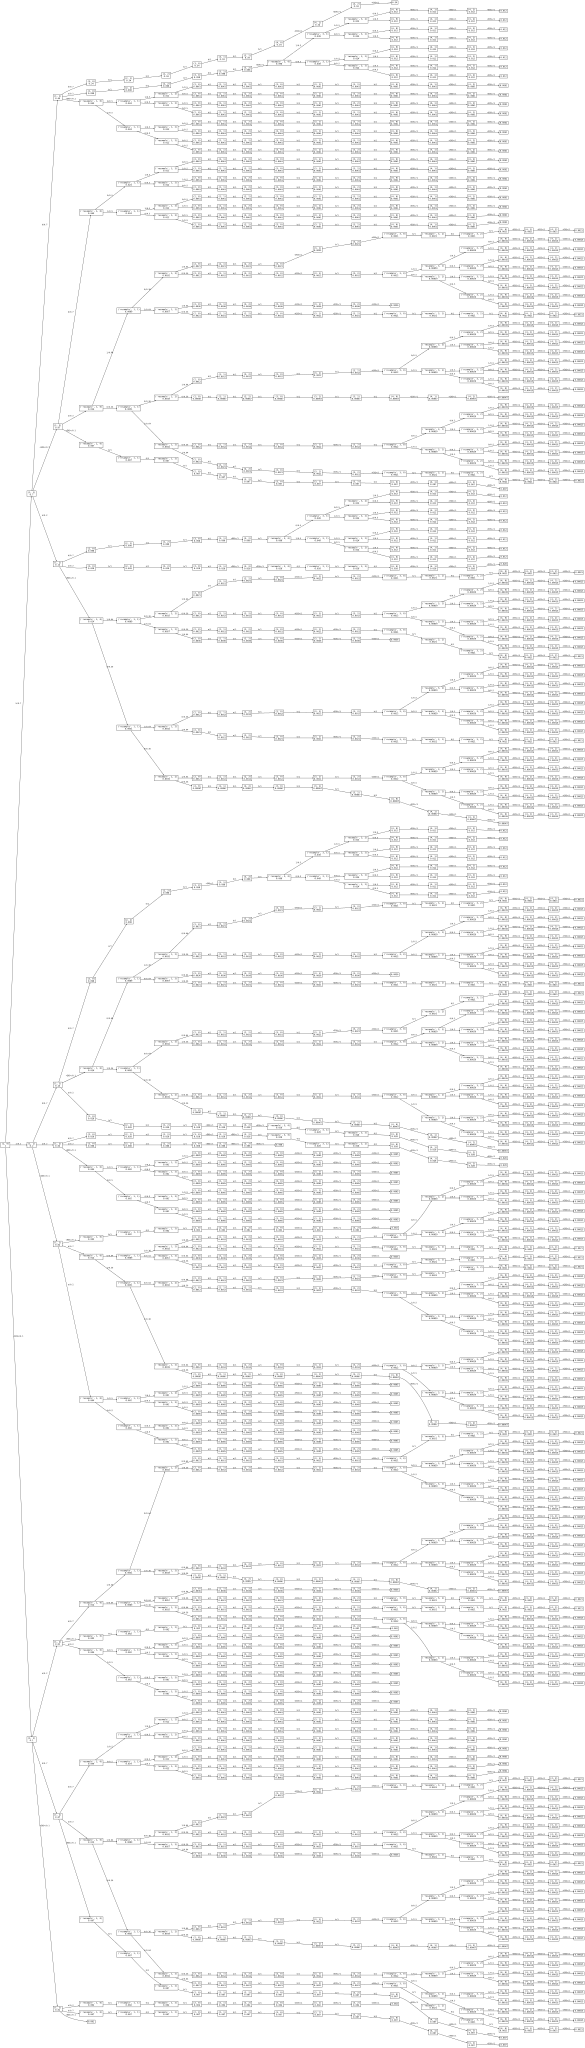

In [10]:
tracer = TraceSWOR()
have = 0
while tracer.root.mass > 0:
    with tracer:
        finished = sequential_importance_resampling(p_lm, q_lm, tau=0.75, M=3, draw=tracer)
        Z_hat = sum(pt.weight for pt in finished) / 3
        have += Z_hat * tracer.cur.mass

print(f'Z estimate (exact via tracing): {have:.6f}')
print(f'Z true:                         1.000000')
assert abs(have - 1.0) < 1e-10
print('\u2713 SIR is unbiased')
tracer.root.graphviz()